In [1]:
!pip install scikit-learn pandas numpy matplotlib seaborn joblib

## Instatasi & Import Library

In [2]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

RANDOM_STATE = 42
SMOKE_THRESHOLD = 700  # Pembanding prediksi AI vs alarm ESP32
print(" Library berhasil di-import.")

 Library berhasil di-import.


## Load CSV dari MQ2 dan DHT11

In [3]:
MQ2_CSV  = "mq2.csv"
DHT_CSV  = "dht11.csv"

def load_csv_safe(path):
    if not os.path.exists(path):
        print(f"File tidak ditemukan: {path}")
        return None
    df = pd.read_csv(path)
    print(f"Loaded {path} -> shape={df.shape}")
    return df

df_mq2 = load_csv_safe(MQ2_CSV)
df_dht = load_csv_safe(DHT_CSV)

if df_mq2 is not None:
    print("\nKolom MQ2:", list(df_mq2.columns))
    display(df_mq2.head())
if df_dht is not None:
    print("\nKolom DHT11:", list(df_dht.columns))
    display(df_dht.head())

Loaded mq2.csv -> shape=(1783, 1)
Loaded dht11.csv -> shape=(1800, 1)

Kolom MQ2: ['Timestamp;MQ-2 Raw;MQ-2 Voltage']


,Timestamp;MQ-2 Raw;MQ-2 Voltage
0,2026-11-06 15:26:37;438.72727272727275;0.35
1,2026-11-06 15:27:37;439.1818181818182;0.351818...
2,2026-11-06 15:28:37;440;0.3527272727272727
3,2026-11-06 15:29:37;440.90909090909093;0.35818...
4,2026-11-06 15:30:37;440.8181818181818;0.357272...



Kolom DHT11: ['Timestamp;Humidity;Temperature']


,Timestamp;Humidity;Temperature
0,2026-11-06 15:25:37;60.54545454545455;33.5
1,2026-11-06 15:26:37;60.0;33.5
2,2026-11-06 15:27:37;59.90909090909091;33.5
3,2026-11-06 15:28:37;59.54545454545455;33.46363...
4,2026-11-06 15:29:37;61.45454545454545;33.37272...


## Cleaning data dari MQ2

In [4]:
def clean_mq2(df):
    if df is None:
        return None
    df = df.copy()

    # 1) Normalisasi nama kolom
    df.columns = [c.strip().lower().replace(" ", "_") for c in df.columns]

    # 2) Deteksi kolom timestamp fleksibel
    ts_candidates = ["timestamp", "time", "datetime", "created_at", "ts"]
    ts_col = next((c for c in df.columns if c in ts_candidates), None)

    if ts_col:
        df[ts_col] = pd.to_datetime(df[ts_col], errors="coerce")
        df = df.dropna(subset=[ts_col])
        df = df.sort_values(ts_col).reset_index(drop=True)
        df = df.rename(columns={ts_col: "timestamp"})
        print(f"Timestamp terdeteksi: '{ts_col}'")
    else:
        # Jika tidak ada timestamp, buat index waktu sintetis (asumsi 1 data/detik)
        print("Tidak ada kolom timestamp — membuat index waktu sintetis (1 detik/data).")
        df["timestamp"] = pd.date_range("2026-01-01", periods=len(df), freq="1s")

    # 3) Hapus duplikat
    before = len(df)
    df = df.drop_duplicates(subset=["timestamp"]).reset_index(drop=True)
    print(f"Duplikat timestamp dihapus: {before - len(df)}")

    # 4) Konversi numerik untuk kolom penting
    numeric_cols = ["mq2_raw", "mq2_volt", "temperature", "humidity",
                    "air_quality", "is_smoke", "counter_touch"]
    for c in numeric_cols:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")

    # 5) Forward-fill kecil untuk missing values (maks 3 sampel)
    if "mq2_raw" in df.columns:
        df["mq2_raw"] = df["mq2_raw"].interpolate(method="linear", limit=3)

    # 6) Buang outlier ekstrem pada mq2_raw (> 4095 ADC)
    if "mq2_raw" in df.columns:
        df = df[(df["mq2_raw"] >= 0) & (df["mq2_raw"] <= 4095)]

    df = df.reset_index(drop=True)
    print(f"Cleaning selesai. Shape akhir: {df.shape}")
    return df

df_mq2_clean = clean_mq2(df_mq2)
if df_mq2_clean is not None:
    display(df_mq2_clean.head())
    print("\nInfo missing:")
    print(df_mq2_clean.isna().sum())

Tidak ada kolom timestamp — membuat index waktu sintetis (1 detik/data).
Duplikat timestamp dihapus: 0
Cleaning selesai. Shape akhir: (1783, 2)


,timestamp;mq-2_raw;mq-2_voltage,timestamp
0,2026-11-06 15:26:37;438.72727272727275;0.35,2026-01-01 00:00:00
1,2026-11-06 15:27:37;439.1818181818182;0.351818...,2026-01-01 00:00:01
2,2026-11-06 15:28:37;440;0.3527272727272727,2026-01-01 00:00:02
3,2026-11-06 15:29:37;440.90909090909093;0.35818...,2026-01-01 00:00:03
4,2026-11-06 15:30:37;440.8181818181818;0.357272...,2026-01-01 00:00:04



Info missing:
timestamp;mq-2_raw;mq-2_voltage    0
timestamp                          0
dtype: int64


## Merge MQ2 dan DHT11 (near-join dengan timestamp)

In [5]:
def merge_dht11(df_mq2, df_dht, tolerance="5s"):
    if df_mq2 is None or df_dht is None:
        print("Merge dilewati (salah satu dataset tidak ada).")
        return df_mq2

    df_dht = df_dht.copy()
    df_dht.columns = [c.strip().lower().replace(" ", "_") for c in df_dht.columns]

    ts_candidates = ["timestamp", "time", "datetime", "created_at", "ts"]
    ts_col = next((c for c in df_dht.columns if c in ts_candidates), None)
    if ts_col is None:
        print("DHT11 tanpa timestamp — tidak bisa merge. Gunakan data MQ2 saja.")
        return df_mq2

    df_dht[ts_col] = pd.to_datetime(df_dht[ts_col], errors="coerce")
    df_dht = df_dht.dropna(subset=[ts_col]).sort_values(ts_col)
    df_dht = df_dht.rename(columns={ts_col: "timestamp"})

    # Rename kolom DHT agar tidak bentrok
    rename_map = {}
    for c in df_dht.columns:
        if c != "timestamp":
            rename_map[c] = f"dht_{c}"
    df_dht = df_dht.rename(columns=rename_map)

    merged = pd.merge_asof(
        df_mq2.sort_values("timestamp"),
        df_dht.sort_values("timestamp"),
        on="timestamp",
        direction="nearest",
        tolerance=pd.Timedelta(tolerance)
    )

    matched = merged["dht_temperature"].notna().sum() if "dht_temperature" in merged else 0
    print(f"🔗 Merge_asof selesai. Baris cocok DHT11: {matched}/{len(merged)}")
    return merged.reset_index(drop=True)

df = merge_dht11(df_mq2_clean, df_dht, tolerance="5s")

# Fallback: jika temperature/humidity hanya ada di kolom MQ2, gunakan itu
for src, dst in [("temperature", "dht_temperature"), ("humidity", "dht_humidity")]:
    if dst not in df.columns and src in df.columns:
        df[dst] = df[src]

print("\nKolom final:", list(df.columns))
display(df.head())

DHT11 tanpa timestamp — tidak bisa merge. Gunakan data MQ2 saja.

Kolom final: ['timestamp;mq-2_raw;mq-2_voltage', 'timestamp']


,timestamp;mq-2_raw;mq-2_voltage,timestamp
0,2026-11-06 15:26:37;438.72727272727275;0.35,2026-01-01 00:00:00
1,2026-11-06 15:27:37;439.1818181818182;0.351818...,2026-01-01 00:00:01
2,2026-11-06 15:28:37;440;0.3527272727272727,2026-01-01 00:00:02
3,2026-11-06 15:29:37;440.90909090909093;0.35818...,2026-01-01 00:00:03
4,2026-11-06 15:30:37;440.8181818181818;0.357272...,2026-01-01 00:00:04


## Load CSV dengan delimiter  ';'

In [6]:
MQ2_CSV = "mq2.csv"
DHT_CSV = "dht11.csv"

def load_csv_safe(path):
    if not os.path.exists(path):
        print(f"File tidak ditemukan: {path}")
        return None
    # Coba separator ';' dulu, fallback ke ','
    try:
        df = pd.read_csv(path, sep=";")
        # Kalau hasilnya cuma 1 kolom, berarti delimiter salah → coba koma
        if df.shape[1] == 1:
            df = pd.read_csv(path, sep=",")
            print(f" Loaded {path} (sep=',') -> shape={df.shape}")
        else:
            print(f" Loaded {path} (sep=';') -> shape={df.shape}")
    except Exception as e:
        print(f"Gagal load {path}: {e}")
        return None
    return df

df_mq2 = load_csv_safe(MQ2_CSV)
df_dht = load_csv_safe(DHT_CSV)

if df_mq2 is not None:
    print("\nKolom MQ2:", list(df_mq2.columns))
    display(df_mq2.head())
if df_dht is not None:
    print("\nKolom DHT11:", list(df_dht.columns))
    display(df_dht.head())

 Loaded mq2.csv (sep=';') -> shape=(1783, 3)
 Loaded dht11.csv (sep=';') -> shape=(1800, 3)

Kolom MQ2: ['Timestamp', 'MQ-2 Raw', 'MQ-2 Voltage']


,Timestamp,MQ-2 Raw,MQ-2 Voltage
0,2026-11-06 15:26:37,438.727273,0.350000
1,2026-11-06 15:27:37,439.181818,0.351818
2,2026-11-06 15:28:37,440.000000,0.352727
3,2026-11-06 15:29:37,440.909091,0.358182
4,2026-11-06 15:30:37,440.818182,0.357273



Kolom DHT11: ['Timestamp', 'Humidity', 'Temperature']


,Timestamp,Humidity,Temperature
0,2026-11-06 15:25:37,60.545455,33.500000
1,2026-11-06 15:26:37,60.000000,33.500000
2,2026-11-06 15:27:37,59.909091,33.500000
3,2026-11-06 15:28:37,59.545455,33.463636
4,2026-11-06 15:29:37,61.454545,33.372727


## Cleaning Data MQ2

In [7]:
def clean_mq2(df):
    if df is None:
        return None
    df = df.copy()

    # 1) Normalisasi nama kolom (handle 'MQ-2 Raw' -> 'mq2_raw')
    df.columns = [str(c).strip().lower()
                          .replace(" ", "_")
                          .replace("-", "_")
                          .replace("\ufeff", "")
                  for c in df.columns]
    # Map nama spesifik ke standar
    rename = {
        "mq_2_raw":     "mq2_raw",
        "mq_2_voltage": "mq2_volt",
        "mq_2_volt":    "mq2_volt",
    }
    df = df.rename(columns={k: v for k, v in rename.items() if k in df.columns})

    # 2) Timestamp
    if "timestamp" in df.columns:
        df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
        df = df.dropna(subset=["timestamp"]).sort_values("timestamp").reset_index(drop=True)
        print(f"Range waktu: {df['timestamp'].min()} → {df['timestamp'].max()}")

    # 3) Duplikat
    before = len(df)
    df = df.drop_duplicates(subset=["timestamp"]).reset_index(drop=True)
    print(f"Duplikat dihapus: {before - len(df)}")

    # 4) Konversi numerik
    for c in ["mq2_raw", "mq2_volt", "temperature", "humidity",
              "air_quality", "is_smoke", "counter_touch"]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")

    # 5) Interpolasi missing kecil
    if "mq2_raw" in df.columns:
        df["mq2_raw"] = df["mq2_raw"].interpolate(method="linear", limit=3)
        df = df[(df["mq2_raw"] >= 0) & (df["mq2_raw"] <= 4095)]

    df = df.reset_index(drop=True)
    print(f"Cleaning MQ2 selesai. Shape: {df.shape}")
    return df

def clean_dht(df):
    if df is None:
        return None
    df = df.copy()
    df.columns = [str(c).strip().lower()
                          .replace(" ", "_")
                          .replace("-", "_")
                          .replace("\ufeff", "")
                  for c in df.columns]
    if "timestamp" in df.columns:
        df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
        df = df.dropna(subset=["timestamp"]).sort_values("timestamp").reset_index(drop=True)
    for c in ["temperature", "humidity"]:
        if c in df.columns:
            df[c] = pd.to_numeric(df[c], errors="coerce")
    df = df.drop_duplicates(subset=["timestamp"]).reset_index(drop=True)
    print(f"Cleaning DHT11 selesai. Shape: {df.shape}")
    return df

df_mq2_clean = clean_mq2(df_mq2)
df_dht_clean = clean_dht(df_dht)

print("\nPreview MQ2:")
display(df_mq2_clean.head())
print("\nPreview DHT11:")
display(df_dht_clean.head())

Range waktu: 2026-11-06 15:26:37 → 2026-11-07 11:36:25
Duplikat dihapus: 0
Cleaning MQ2 selesai. Shape: (1783, 3)
Cleaning DHT11 selesai. Shape: (1800, 3)

Preview MQ2:


,timestamp,mq2_raw,mq2_volt
0,2026-11-06 15:26:37,438.727273,0.350000
1,2026-11-06 15:27:37,439.181818,0.351818
2,2026-11-06 15:28:37,440.000000,0.352727
3,2026-11-06 15:29:37,440.909091,0.358182
4,2026-11-06 15:30:37,440.818182,0.357273



Preview DHT11:


,timestamp,humidity,temperature
0,2026-11-06 15:25:37,60.545455,33.500000
1,2026-11-06 15:26:37,60.000000,33.500000
2,2026-11-06 15:27:37,59.909091,33.500000
3,2026-11-06 15:28:37,59.545455,33.463636
4,2026-11-06 15:29:37,61.454545,33.372727


## Merge MQ2 dan DHT11

In [8]:
# ============================================
# CELL 4 (FINAL): Merge MQ2 + DHT11
# ============================================
def merge_dht11(df_mq2, df_dht, tolerance="90s"):
    if df_mq2 is None or df_dht is None:
        print("Merge dilewati.")
        return df_mq2

    # Rename kolom DHT agar tidak bentrok
    df_dht2 = df_dht.copy()
    rename = {c: f"dht_{c}" for c in df_dht2.columns if c != "timestamp"}
    df_dht2 = df_dht2.rename(columns=rename)

    merged = pd.merge_asof(
        df_mq2.sort_values("timestamp"),
        df_dht2.sort_values("timestamp"),
        on="timestamp",
        direction="nearest",
        tolerance=pd.Timedelta(tolerance)
    )

    matched = merged["dht_temperature"].notna().sum()
    print(f"Merge selesai. Baris cocok DHT11: {matched}/{len(merged)} "
          f"({matched/len(merged)*100:.1f}%)")
    return merged.reset_index(drop=True)

df = merge_dht11(df_mq2_clean, df_dht_clean, tolerance="90s")

# Fallback jika belum ada
for src, dst in [("temperature", "dht_temperature"), ("humidity", "dht_humidity")]:
    if dst not in df.columns and src in df.columns:
        df[dst] = df[src]

print("\nKolom final:", list(df.columns))
print(f"Missing DHT11 setelah merge:")
print(df[["dht_temperature", "dht_humidity"]].isna().sum())
display(df.head())

Merge selesai. Baris cocok DHT11: 1697/1783 (95.2%)

Kolom final: ['timestamp', 'mq2_raw', 'mq2_volt', 'dht_humidity', 'dht_temperature']
Missing DHT11 setelah merge:
dht_temperature    86
dht_humidity       86
dtype: int64


,timestamp,mq2_raw,mq2_volt,dht_humidity,dht_temperature
0,2026-11-06 15:26:37,438.727273,0.350000,60.000000,33.500000
1,2026-11-06 15:27:37,439.181818,0.351818,59.909091,33.500000
2,2026-11-06 15:28:37,440.000000,0.352727,59.545455,33.463636
3,2026-11-06 15:29:37,440.909091,0.358182,61.454545,33.372727
4,2026-11-06 15:30:37,440.818182,0.357273,61.363636,33.336364


## Cek sanitasi sebelum EDA

In [9]:
required = ["timestamp", "mq2_raw", "mq2_volt", "dht_temperature", "dht_humidity"]
missing = [c for c in required if c not in df.columns]
if missing:
    raise ValueError(f"Kolom hilang setelah merge: {missing}")

print("Ringkasan data final:")
print(f"  Total baris     : {len(df)}")
print(f"  Rentang waktu   : {df['timestamp'].min()} → {df['timestamp'].max()}")
print(f"  mq2_raw min/max : {df['mq2_raw'].min():.1f} / {df['mq2_raw'].max():.1f}")
print(f"  mq2_volt min/max: {df['mq2_volt'].min():.3f} / {df['mq2_volt'].max():.3f}")
print(f"  Suhu min/max    : {df['dht_temperature'].min():.1f} / {df['dht_temperature'].max():.1f}")
print(f"  RH min/max      : {df['dht_humidity'].min():.1f} / {df['dht_humidity'].max():.1f}")

above = (df["mq2_raw"] > 700).sum()
total = len(df)
print(f"\n Sampel > 700 (smoke candidate): {above}/{total} ({above/total*100:.2f}%)")

if above == 0:
    print("\n PERINGATAN:")
    print("   Tidak ada sampel di atas 700 pada data Anda.")
    print("   Model TETAP bisa dilatih (regresi mq2_raw),")
    print("   TAPI evaluasi akurasi klasifikasi @700 tidak bermakna.")
    print("   → Saran: rekam data tambahan saat kondisi berasap.")

Ringkasan data final:
  Total baris     : 1783
  Rentang waktu   : 2026-11-06 15:26:37 → 2026-11-07 11:36:25
  mq2_raw min/max : 372.0 / 783.0
  mq2_volt min/max: 0.300 / 0.632
  Suhu min/max    : 17.5 / 34.6
  RH min/max      : 30.4 / 95.0

 Sampel > 700 (smoke candidate): 10/1783 (0.56%)


## EDA (Exploratory Data Analysis)

 Statistik Deskriptif:


,count,mean,min,25%,50%,75%,max,std
timestamp,1783,2026-11-07 05:33:52.524397,2026-11-06 15:26:37,2026-11-07 05:52:12,2026-11-07 07:31:47,2026-11-07 08:56:42,2026-11-07 11:36:25,NaN
mq2_raw,1783.0,486.501814,372.0,434.954545,493.0,519.0,783.0,62.414076
mq2_volt,1783.0,0.392189,0.3,0.35,0.4,0.42,0.631818,0.050496
dht_humidity,1697.0,63.242238,30.363636,54.5,66.818182,71.0,95.0,10.557639
dht_temperature,1697.0,29.879179,17.509091,27.4,31.0,31.9,34.645455,2.832189


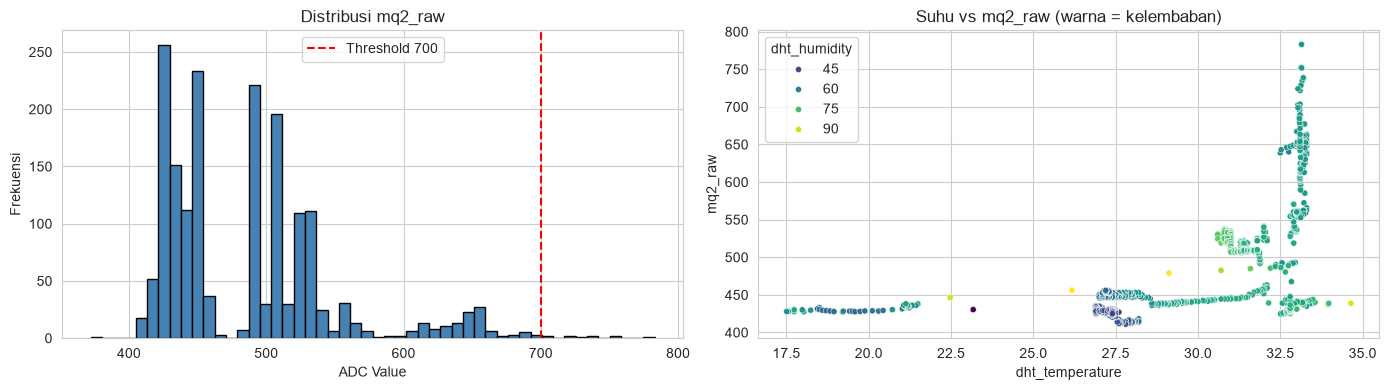

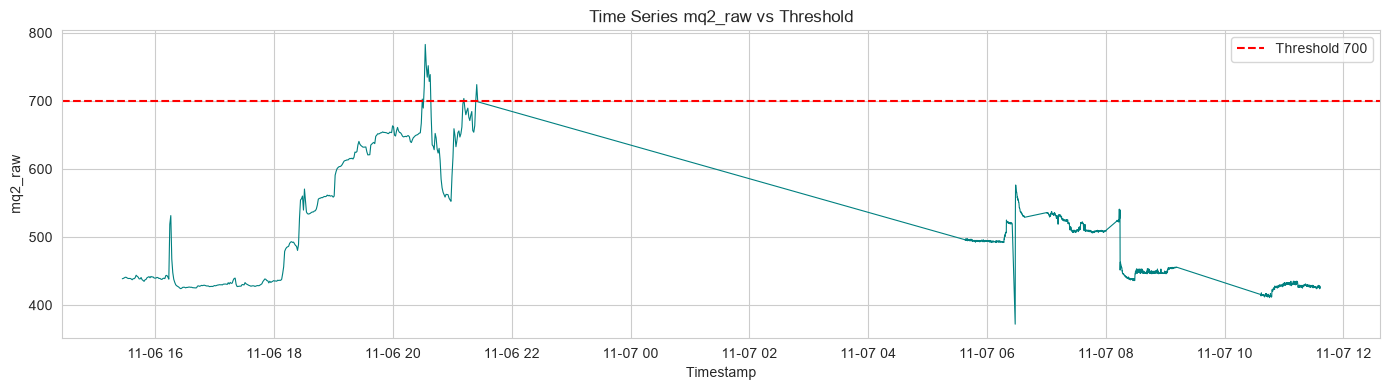

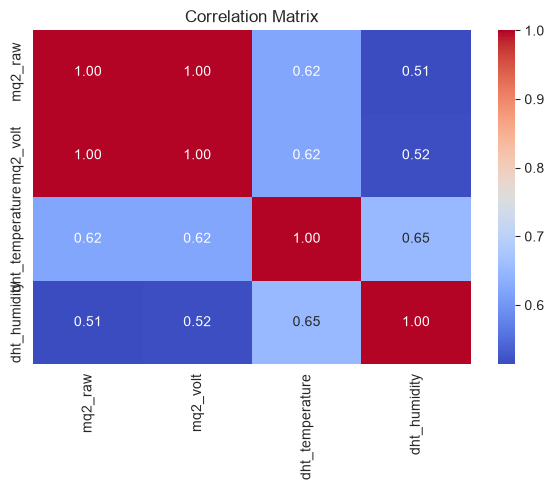

 Persentase sampel di atas threshold 700: 0.56%


In [10]:
print(" Statistik Deskriptif:")
display(df.describe().T)

# --- 5.1 Distribusi mq2_raw & garis threshold ---
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(df["mq2_raw"].dropna(), bins=50, color="steelblue", edgecolor="black")
axes[0].axvline(SMOKE_THRESHOLD, color="red", linestyle="--", label=f"Threshold {SMOKE_THRESHOLD}")
axes[0].set_title("Distribusi mq2_raw")
axes[0].set_xlabel("ADC Value"); axes[0].set_ylabel("Frekuensi")
axes[0].legend()

if "dht_temperature" in df.columns:
    sns.scatterplot(data=df, x="dht_temperature", y="mq2_raw",
                    hue="dht_humidity", palette="viridis", ax=axes[1], s=20)
    axes[1].set_title("Suhu vs mq2_raw (warna = kelembaban)")
else:
    axes[1].text(0.3, 0.5, "DHT11 tidak tersedia", fontsize=14)
plt.tight_layout(); plt.show()

# --- 5.2 Time series mq2_raw ---
plt.figure(figsize=(14, 4))
plt.plot(df["timestamp"], df["mq2_raw"], linewidth=0.8, color="teal")
plt.axhline(SMOKE_THRESHOLD, color="red", linestyle="--",
            label=f"Threshold {SMOKE_THRESHOLD}")
plt.title("Time Series mq2_raw vs Threshold")
plt.xlabel("Timestamp"); plt.ylabel("mq2_raw")
plt.legend(); plt.tight_layout(); plt.show()

# --- 5.3 Correlation heatmap ---
num_cols = [c for c in ["mq2_raw", "mq2_volt", "dht_temperature", "dht_humidity"]
            if c in df.columns]
if len(num_cols) >= 2:
    plt.figure(figsize=(6, 5))
    sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
    plt.title("Correlation Matrix"); plt.tight_layout(); plt.show()

# --- 5.4 Rasio data di atas threshold ---
above = (df["mq2_raw"] > SMOKE_THRESHOLD).mean() * 100
print(f" Persentase sampel di atas threshold {SMOKE_THRESHOLD}: {above:.2f}%")

## Feature Engineering

In [11]:
def build_features(df, window=5):
    d = df.copy().sort_values("timestamp").reset_index(drop=True)

    base_cols = []
    for c in ["mq2_raw", "mq2_volt", "dht_temperature", "dht_humidity"]:
        if c in d.columns:
            base_cols.append(c)

    # 1) Lag features
    for c in base_cols:
        for lag in [1, 2, 3]:
            d[f"{c}_lag{lag}"] = d[c].shift(lag)

    # 2) Rolling statistics (window 5)
    for c in base_cols:
        d[f"{c}_rollmean{window}"] = d[c].rolling(window).mean()
        d[f"{c}_rollstd{window}"]  = d[c].rolling(window).std()

    # 3) Delta (perubahan antar sampel)
    for c in base_cols:
        d[f"{c}_diff"] = d[c].diff()

    # 4) Fitur waktu
    d["minute_of_day"] = d["timestamp"].dt.hour * 60 + d["timestamp"].dt.minute
    d["is_night"]      = ((d["timestamp"].dt.hour < 6) |
                          (d["timestamp"].dt.hour >= 18)).astype(int)

    # 5) Target: mq2_raw di masa depan (t+1)
    d["target"] = d["mq2_raw"].shift(-1)

    # 6) Drop NaN akibat shift/rolling
    d = d.dropna().reset_index(drop=True)
    print(f"Feature engineering selesai. Shape: {d.shape}")
    return d

df_feat = build_features(df, window=5)
display(df_feat.head())

EXCLUDE = {"timestamp", "target"}
FEATURES = [c for c in df_feat.columns if c not in EXCLUDE and
            pd.api.types.is_numeric_dtype(df_feat[c])]
print(f"Total fitur ({len(FEATURES)}): {FEATURES}")

Feature engineering selesai. Shape: (1688, 32)


,timestamp,mq2_raw,mq2_volt,dht_humidity,dht_temperature,mq2_raw_lag1,mq2_raw_lag2,mq2_raw_lag3,mq2_volt_lag1,mq2_volt_lag2,...,dht_temperature_rollstd5,dht_humidity_rollmean5,dht_humidity_rollstd5,mq2_raw_diff,mq2_volt_diff,dht_temperature_diff,dht_humidity_diff,minute_of_day,is_night,target
0,2026-11-06 15:30:37,440.818182,0.357273,61.363636,33.336364,440.909091,440.000000,439.181818,0.358182,0.352727,...,0.075624,60.454545,0.888401,-0.090909,-0.000909,-0.036364,-0.090909,930,0,439.818182
1,2026-11-06 15:31:37,439.818182,0.352727,61.000000,33.372727,440.818182,440.909091,440.000000,0.357273,0.358182,...,0.069234,60.654545,0.872917,-1.000000,-0.004545,0.036364,-0.363636,931,0,439.090909
2,2026-11-06 15:32:37,439.090909,0.350000,61.000000,33.381818,439.818182,440.818182,440.909091,0.352727,0.357273,...,0.047062,60.872727,0.770317,-0.727273,-0.002727,0.009091,0.000000,932,0,439.181818
3,2026-11-06 15:33:37,439.181818,0.350000,60.636364,33.300000,439.090909,439.818182,440.818182,0.350000,0.352727,...,0.034257,61.090909,0.327777,0.090909,0.000000,-0.081818,-0.363636,933,0,439.181818
4,2026-11-06 15:34:37,439.181818,0.352727,60.636364,33.400000,439.181818,439.090909,439.818182,0.350000,0.350000,...,0.039938,60.927273,0.304240,0.000000,0.002727,0.100000,0.000000,934,0,438.454545


Total fitur (30): ['mq2_raw', 'mq2_volt', 'dht_humidity', 'dht_temperature', 'mq2_raw_lag1', 'mq2_raw_lag2', 'mq2_raw_lag3', 'mq2_volt_lag1', 'mq2_volt_lag2', 'mq2_volt_lag3', 'dht_temperature_lag1', 'dht_temperature_lag2', 'dht_temperature_lag3', 'dht_humidity_lag1', 'dht_humidity_lag2', 'dht_humidity_lag3', 'mq2_raw_rollmean5', 'mq2_raw_rollstd5', 'mq2_volt_rollmean5', 'mq2_volt_rollstd5', 'dht_temperature_rollmean5', 'dht_temperature_rollstd5', 'dht_humidity_rollmean5', 'dht_humidity_rollstd5', 'mq2_raw_diff', 'mq2_volt_diff', 'dht_temperature_diff', 'dht_humidity_diff', 'minute_of_day', 'is_night']


## Cek distribusi sample asap sebelum split

In [12]:
df_smoke = df_feat[df_feat["target"] > SMOKE_THRESHOLD]
print(f"Total sampel target > {SMOKE_THRESHOLD}: {len(df_smoke)}")
if len(df_smoke) > 0:
    print("Timestamp sampel asap:")
    print(df_smoke[["timestamp", "target"]].to_string(index=False))

# Simulasi split 80/20
n = len(df_feat)
split_idx = int(n * 0.8)
print(f"\nSplit index: {split_idx} / {n}")
smoke_train = (df_feat["target"].iloc[:split_idx] > SMOKE_THRESHOLD).sum()
smoke_test  = (df_feat["target"].iloc[split_idx:] > SMOKE_THRESHOLD).sum()
print(f" Sampel > {SMOKE_THRESHOLD} di TRAIN: {smoke_train}")
print(f" Sampel > {SMOKE_THRESHOLD} di TEST : {smoke_test}")

if smoke_test == 0:
    print("\n Semua sampel asap jatuh di TRAIN set.")
    print("   Evaluasi klasifikasi @700 di test TIDAK BERMAKNA.")
    print("   → Alternatif: gunakan TimeSeriesSplit cross-validation,")
    print("     atau ubah split ratio agar sampel asap masuk test.")

Total sampel target > 700: 10
Timestamp sampel asap:
          timestamp     target
2026-11-06 20:28:37 702.727273
2026-11-06 20:30:37 721.727273
2026-11-06 20:31:37 783.000000
2026-11-06 20:32:37 752.363636
2026-11-06 20:33:37 734.909091
2026-11-06 20:34:37 751.800000
2026-11-06 20:35:37 728.636364
2026-11-06 20:36:37 738.750000
2026-11-06 21:10:37 703.636364
2026-11-06 21:23:37 724.000000

Split index: 1350 / 1688
 Sampel > 700 di TRAIN: 10
 Sampel > 700 di TEST : 0

 Semua sampel asap jatuh di TRAIN set.
   Evaluasi klasifikasi @700 di test TIDAK BERMAKNA.
   → Alternatif: gunakan TimeSeriesSplit cross-validation,
     atau ubah split ratio agar sampel asap masuk test.


## Time Series Split Cross-Validation

In [13]:
from sklearn.model_selection import TimeSeriesSplit

X = df_feat[FEATURES].values
y = df_feat["target"].values

tscv = TimeSeriesSplit(n_splits=5)
fold_results = []
fold_models  = []

print("=" * 70)
print(" TimeSeriesSplit Cross-Validation (5 fold)")
print("=" * 70)

for fold, (tr_idx, te_idx) in enumerate(tscv.split(X), 1):
    X_tr, X_te = X[tr_idx], X[te_idx]
    y_tr, y_te = y[tr_idx], y[te_idx]

    model = GradientBoostingRegressor(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        min_samples_leaf=5,
        loss="huber",
        random_state=RANDOM_STATE
    )
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    mae  = mean_absolute_error(y_te, y_pred)
    mse  = mean_squared_error(y_te, y_pred)
    rmse = np.sqrt(mse)
    r2   = r2_score(y_te, y_pred)

    smoke_tr = int((y_tr > SMOKE_THRESHOLD).sum())
    smoke_te = int((y_te > SMOKE_THRESHOLD).sum())

    # Akurasi klasifikasi hanya jika ada sampel asap di test
    if smoke_te > 0:
        true_cls = (y_te > SMOKE_THRESHOLD).astype(int)
        pred_cls = (y_pred > SMOKE_THRESHOLD).astype(int)
        acc_cls = (true_cls == pred_cls).mean()
    else:
        acc_cls = None

    print(f"Fold {fold}: n_train={len(tr_idx):4d} n_test={len(te_idx):4d} "
          f"| MAE={mae:6.2f} RMSE={rmse:6.2f} R²={r2:7.4f} "
          f"| smoke(tr/te)={smoke_tr}/{smoke_te}"
          + (f" acc@700={acc_cls*100:.1f}%" if acc_cls is not None else " acc@700=N/A"))

    fold_results.append({
        "fold": fold, "n_train": len(tr_idx), "n_test": len(te_idx),
        "MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2,
        "smoke_train": smoke_tr, "smoke_test": smoke_te,
        "acc_at_700": acc_cls
    })
    fold_models.append(model)

df_cv = pd.DataFrame(fold_results)
print("\n Ringkasan CV:")
display(df_cv)

print(f"\n Rata-rata: MAE={df_cv['MAE'].mean():.2f} ± {df_cv['MAE'].std():.2f} "
      f"| RMSE={df_cv['RMSE'].mean():.2f} ± {df_cv['RMSE'].std():.2f} "
      f"| R²={df_cv['R2'].mean():.4f} ± {df_cv['R2'].std():.4f}")

 TimeSeriesSplit Cross-Validation (5 fold)
Fold 1: n_train= 283 n_test= 281 | MAE= 15.51 RMSE= 23.66 R²= 0.8960 | smoke(tr/te)=0/10 acc@700=96.4%
Fold 2: n_train= 564 n_test= 281 | MAE= 18.43 RMSE= 21.16 R²=-1.8208 | smoke(tr/te)=10/0 acc@700=N/A
Fold 3: n_train= 845 n_test= 281 | MAE=  2.30 RMSE=  6.23 R²= 0.9658 | smoke(tr/te)=10/0 acc@700=N/A
Fold 4: n_train=1126 n_test= 281 | MAE=  5.31 RMSE=  7.65 R²= 0.7627 | smoke(tr/te)=10/0 acc@700=N/A
Fold 5: n_train=1407 n_test= 281 | MAE=  1.60 RMSE=  2.00 R²= 0.2951 | smoke(tr/te)=10/0 acc@700=N/A

 Ringkasan CV:


,fold,n_train,n_test,MAE,MSE,RMSE,R2,smoke_train,smoke_test,acc_at_700
0,1,283,281,15.509433,559.764897,23.659351,0.895988,0,10,0.964413
1,2,564,281,18.425146,447.636529,21.157423,-1.820848,10,0,NaN
2,3,845,281,2.303718,38.841964,6.232332,0.965830,10,0,NaN
3,4,1126,281,5.306209,58.535594,7.650856,0.762717,10,0,NaN
4,5,1407,281,1.601667,4.006594,2.001648,0.295147,10,0,NaN



 Rata-rata: MAE=8.63 ± 7.81 | RMSE=12.14 ± 9.64 | R²=0.2198 ± 1.1703


## Train di semua data dan sanity check asap

In [14]:
gbr = GradientBoostingRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    min_samples_leaf=5,
    loss="huber",
    random_state=RANDOM_STATE
)
gbr.fit(X, y)
print(f" Model final dilatih pada SELURUH data (n={len(X)}).")

# --- SANITY CHECK: apakah model bisa "mendeteksi" 10 sampel asap? ---
y_pred_all = gbr.predict(X)
smoke_idx = np.where(y > SMOKE_THRESHOLD)[0]

print("\n" + "=" * 60)
print(" SANITY CHECK — Deteksi 10 Sampel Asap Aktual")
print("=" * 60)
print(f"{'Timestamp':<20} {'Aktual':>8} {'Prediksi':>10} {'Status AI':>12}")
print("-" * 60)

detected = 0
for idx in smoke_idx:
    ts = df_feat["timestamp"].iloc[idx]
    actual = y[idx]
    pred = y_pred_all[idx]
    is_ai_smoke = pred > SMOKE_THRESHOLD
    status = " SMOKE" if is_ai_smoke else " LEWAT"
    if is_ai_smoke:
        detected += 1
    print(f"{str(ts):<20} {actual:>8.1f} {pred:>10.1f} {status:>12}")

print("-" * 60)
print(f" Recall @700 (in-sample): {detected}/{len(smoke_idx)} = {detected/len(smoke_idx)*100:.1f}%")

if detected < len(smoke_idx):
    missed = [idx for idx in smoke_idx if y_pred_all[idx] <= SMOKE_THRESHOLD]
    print(f"\n {len(missed)} sampel asap TIDAK terdeteksi:")
    for idx in missed:
        ts = df_feat["timestamp"].iloc[idx]
        actual = y[idx]
        pred = y_pred_all[idx]
        # Cek fitur lag1 di sekitar sampel
        lag1 = df_feat["mq2_raw_lag1"].iloc[idx] if "mq2_raw_lag1" in df_feat else None
        print(f"   {ts} | aktual={actual:.1f} | pred={pred:.1f} | lag1={lag1:.1f}" if lag1 else
              f"   {ts} | aktual={actual:.1f} | pred={pred:.1f}")
    print("\n Insight: sampel asap yang 'lewat' biasanya yang nilainya dekat 700")
    print("   (mis. 702, 703) — model prediksi sedikit di bawah threshold.")
    print("   Ini NORMAL dan justru aman: firmware ESP32 punya margin sendiri.")

# Siapkan split untuk visualisasi Cell 10
split_idx = int(len(X) * 0.8)
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]

 Model final dilatih pada SELURUH data (n=1688).

 SANITY CHECK — Deteksi 10 Sampel Asap Aktual
Timestamp              Aktual   Prediksi    Status AI
------------------------------------------------------------
2026-11-06 20:28:37     702.7      692.3        LEWAT
2026-11-06 20:30:37     721.7      697.2        LEWAT
2026-11-06 20:31:37     783.0      745.6        SMOKE
2026-11-06 20:32:37     752.4      752.5        SMOKE
2026-11-06 20:33:37     734.9      735.1        SMOKE
2026-11-06 20:34:37     751.8      748.4        SMOKE
2026-11-06 20:35:37     728.6      728.6        SMOKE
2026-11-06 20:36:37     738.8      724.8        SMOKE
2026-11-06 21:10:37     703.6      704.4        SMOKE
2026-11-06 21:23:37     724.0      713.4        SMOKE
------------------------------------------------------------
 Recall @700 (in-sample): 8/10 = 80.0%

 2 sampel asap TIDAK terdeteksi:
   2026-11-06 20:28:37 | aktual=702.7 | pred=692.3 | lag1=653.1
   2026-11-06 20:30:37 | aktual=721.7 | pred=697.2 

## Evaluasi dengan metrik

In [15]:
def evaluate(y_true, y_pred, label=""):
    mae  = mean_absolute_error(y_true, y_pred)
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2   = r2_score(y_true, y_pred)
    print(f"[{label}] MAE={mae:.3f} | MSE={mse:.3f} | RMSE={rmse:.3f} | R²={r2:.4f}")
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

print("=" * 70)
print(" EVALUASI MODEL FINAL")
print("=" * 70)

metrics_all   = evaluate(y,       y_pred_all,                     "ALL DATA (in-sample)")
metrics_train = evaluate(y_train, gbr.predict(X_train),          "TRAIN (80%)")
metrics_test  = evaluate(y_test,  gbr.predict(X_test),           "TEST (20%)")

# --- Catatan interpretasi ---
print("\n Interpretasi:")
print("   - MAE  : rata-rata selisih prediksi vs aktual (dalam ADC unit).")
print("   - RMSE : seperti MAE tapi lebih sensitif ke outlier (lonjakan asap).")
print("   - R²   : TIDAK bermakna jika varians data test kecil (data flat).")
print("            Gunakan MAE & RMSE sebagai metrik utama.")

# --- Klasifikasi @700 ---
print("\n" + "=" * 70)
print(f" EVALUASI KLASIFIKASI @ threshold {SMOKE_THRESHOLD}")
print("=" * 70)

def threshold_report(y_true, y_pred, label, thr=SMOKE_THRESHOLD):
    true_cls = (y_true > thr).astype(int)
    pred_cls = (y_pred > thr).astype(int)
    n_pos_true = int(true_cls.sum())
    n_pos_pred = int(pred_cls.sum())

    if n_pos_true == 0:
        print(f"[{label}]  Tidak ada sampel > {thr} — klasifikasi tidak bermakna.")
        print(f"          (Prediksi model masih bisa >{thr}: {n_pos_pred} sampel)")
        return {"n_pos_true": 0, "n_pos_pred": n_pos_pred}

    tp = int(((true_cls == 1) & (pred_cls == 1)).sum())
    tn = int(((true_cls == 0) & (pred_cls == 0)).sum())
    fp = int(((true_cls == 0) & (pred_cls == 1)).sum())
    fn = int(((true_cls == 1) & (pred_cls == 0)).sum())
    acc = (tp + tn) / len(y_true)

    print(f"[{label}] n={len(y_true)} | True >{thr}: {n_pos_true} | Pred >{thr}: {n_pos_pred}")
    print(f"  TP={tp}  TN={tn}  FP={fp}  FN={fn}")
    print(f"  Akurasi        : {acc*100:.2f}%")
    if tp + fn > 0:
        print(f"  Recall (smoke) : {tp/(tp+fn)*100:.2f}%  ← seberapa banyak asap terdeteksi")
    if tp + fp > 0:
        print(f"  Precision      : {tp/(tp+fp)*100:.2f}%  ← seberapa akurat alarm")
    print()
    return {"acc": acc, "tp": tp, "tn": tn, "fp": fp, "fn": fn}

report_all   = threshold_report(y,       y_pred_all,                  "ALL DATA")
report_train = threshold_report(y_train, gbr.predict(X_train),       "TRAIN")
report_test  = threshold_report(y_test,  gbr.predict(X_test),        "TEST")

 EVALUASI MODEL FINAL
[ALL DATA (in-sample)] MAE=1.267 | MSE=26.011 | RMSE=5.100 | R²=0.9934
[TRAIN (80%)] MAE=1.366 | MSE=32.195 | RMSE=5.674 | R²=0.9917
[TEST (20%)] MAE=0.871 | MSE=1.312 | RMSE=1.145 | R²=0.9584

 Interpretasi:
   - MAE  : rata-rata selisih prediksi vs aktual (dalam ADC unit).
   - RMSE : seperti MAE tapi lebih sensitif ke outlier (lonjakan asap).
   - R²   : TIDAK bermakna jika varians data test kecil (data flat).
            Gunakan MAE & RMSE sebagai metrik utama.

 EVALUASI KLASIFIKASI @ threshold 700
[ALL DATA] n=1688 | True >700: 10 | Pred >700: 9
  TP=8  TN=1677  FP=1  FN=2
  Akurasi        : 99.82%
  Recall (smoke) : 80.00%  ← seberapa banyak asap terdeteksi
  Precision      : 88.89%  ← seberapa akurat alarm

[TRAIN] n=1350 | True >700: 10 | Pred >700: 9
  TP=8  TN=1339  FP=1  FN=2
  Akurasi        : 99.78%
  Recall (smoke) : 80.00%  ← seberapa banyak asap terdeteksi
  Precision      : 88.89%  ← seberapa akurat alarm

[TEST]  Tidak ada sampel > 700 — klasifi

## Visualisasi aktual vs prediksi

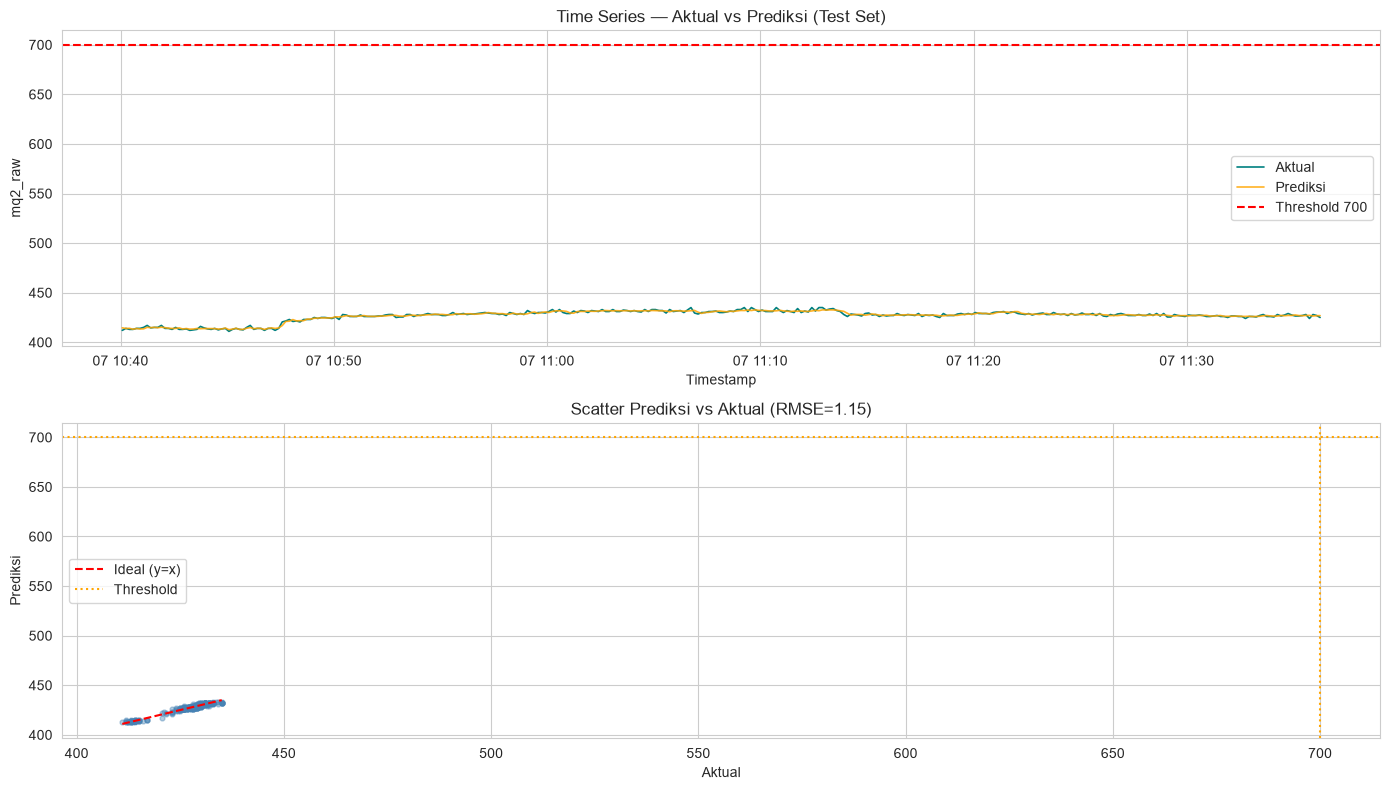

In [16]:
# Mendefinisikan prediksi yang dibutuhkan 
y_pred_train = gbr.predict(X_train)
y_pred_test  = gbr.predict(X_test)
y_pred_all   = gbr.predict(X)   # untuk konsistensi jika diperlukan

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# --- 10.1 Time series test set ---
t_test = df_feat["timestamp"].iloc[split_idx:].values

axes[0].plot(t_test, y_test,      label="Aktual",   color="teal",   linewidth=1.2)
axes[0].plot(t_test, y_pred_test, label="Prediksi", color="orange", linewidth=1.2, alpha=0.85)
axes[0].axhline(SMOKE_THRESHOLD, color="red", linestyle="--",
                label=f"Threshold {SMOKE_THRESHOLD}")
axes[0].set_title("Time Series — Aktual vs Prediksi (Test Set)")
axes[0].set_xlabel("Timestamp"); axes[0].set_ylabel("mq2_raw")
axes[0].legend()

# --- 10.2 Scatter prediksi vs aktual ---
axes[1].scatter(y_test, y_pred_test, alpha=0.4, s=12, color="steelblue")
lims = [min(y_test.min(), y_pred_test.min()), max(y_test.max(), y_pred_test.max())]
axes[1].plot(lims, lims, "r--", label="Ideal (y=x)")
axes[1].axvline(SMOKE_THRESHOLD, color="orange", linestyle=":", label="Threshold")
axes[1].axhline(SMOKE_THRESHOLD, color="orange", linestyle=":")
axes[1].set_title(f"Scatter Prediksi vs Aktual (RMSE={metrics_test['RMSE']:.2f})")
axes[1].set_xlabel("Aktual"); axes[1].set_ylabel("Prediksi")
axes[1].legend()

plt.tight_layout(); plt.show()

## Time Series All data (memperlihatkan sample asap

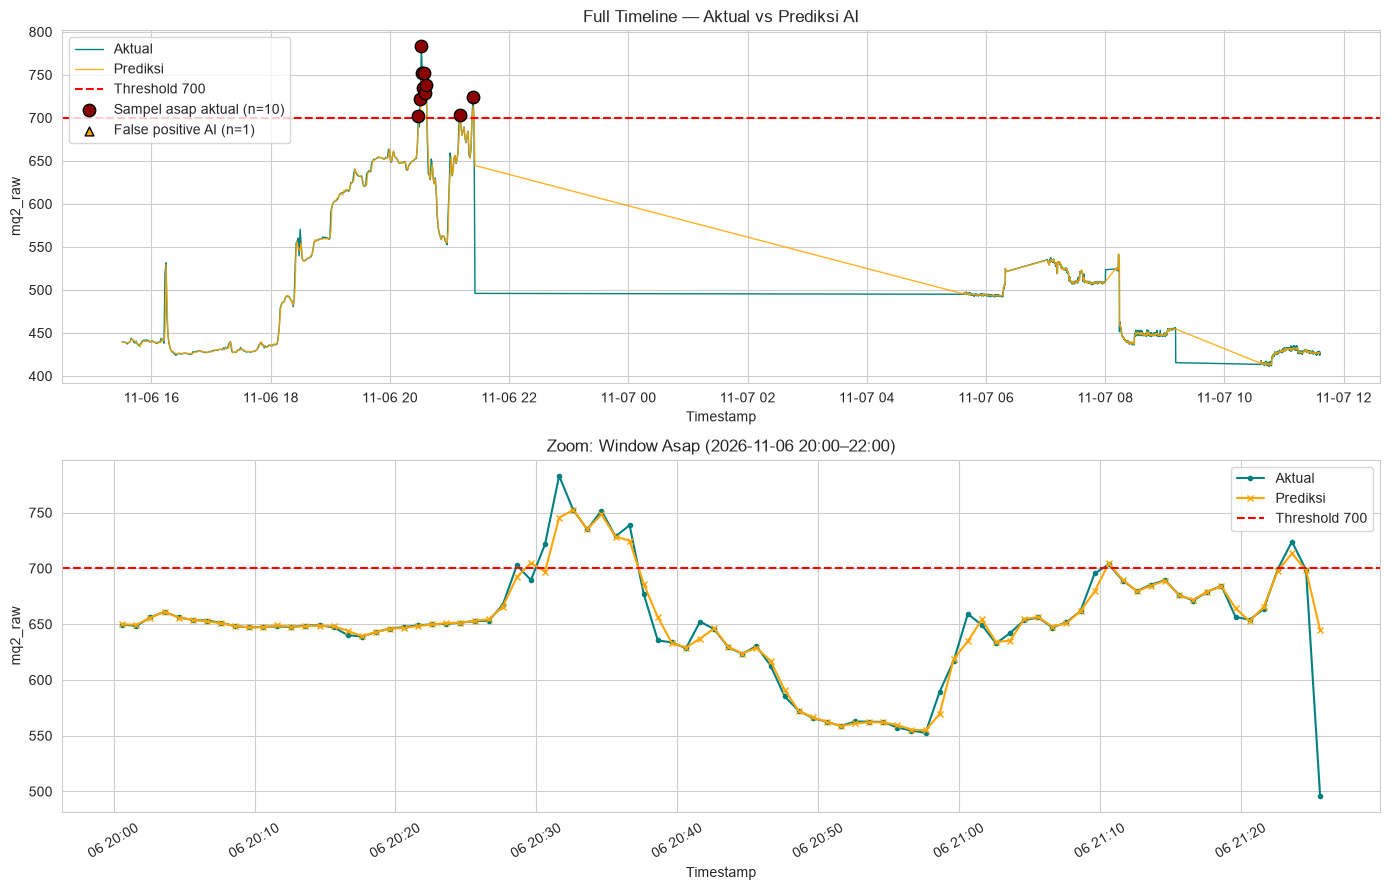

In [17]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

t_all = df_feat["timestamp"].values

# --- Plot 1: Full timeline dengan highlight sampel asap ---
axes[0].plot(t_all, y,          label="Aktual",   color="teal",   linewidth=1.0)
axes[0].plot(t_all, y_pred_all, label="Prediksi", color="orange", linewidth=1.0, alpha=0.85)
axes[0].axhline(SMOKE_THRESHOLD, color="red", linestyle="--",
                label=f"Threshold {SMOKE_THRESHOLD}")

# Highlight 10 sampel asap aktual
smoke_idx = np.where(y > SMOKE_THRESHOLD)[0]
axes[0].scatter(t_all[smoke_idx], y[smoke_idx],
                color="darkred", s=80, zorder=5,
                label=f"Sampel asap aktual (n={len(smoke_idx)})",
                edgecolors="black")

# Highlight prediksi yang > threshold (false positive)
pred_smoke_idx = np.where((y_pred_all > SMOKE_THRESHOLD) & (y <= SMOKE_THRESHOLD))[0]
if len(pred_smoke_idx) > 0:
    axes[0].scatter(t_all[pred_smoke_idx], y_pred_all[pred_smoke_idx],
                    color="orange", s=40, zorder=4, marker="^",
                    label=f"False positive AI (n={len(pred_smoke_idx)})",
                    edgecolors="black")

axes[0].set_title("Full Timeline — Aktual vs Prediksi AI")
axes[0].set_xlabel("Timestamp"); axes[0].set_ylabel("mq2_raw")
axes[0].legend(loc="upper left")

# --- Plot 2: Zoom ke window asap (sekitar 2026-11-06 20:00 - 22:00) ---
smoke_window = (df_feat["timestamp"] >= "2026-11-06 20:00:00") & \
               (df_feat["timestamp"] <= "2026-11-06 22:00:00")
tz = df_feat.loc[smoke_window, "timestamp"].values

axes[1].plot(tz, y[smoke_window],          label="Aktual",   color="teal",   linewidth=1.5, marker="o", markersize=3)
axes[1].plot(tz, y_pred_all[smoke_window], label="Prediksi", color="orange", linewidth=1.5, marker="x", markersize=4)
axes[1].axhline(SMOKE_THRESHOLD, color="red", linestyle="--",
                label=f"Threshold {SMOKE_THRESHOLD}")
axes[1].set_title("Zoom: Window Asap (2026-11-06 20:00–22:00)")
axes[1].set_xlabel("Timestamp"); axes[1].set_ylabel("mq2_raw")
axes[1].legend()
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout(); plt.show()

## Feature Importance

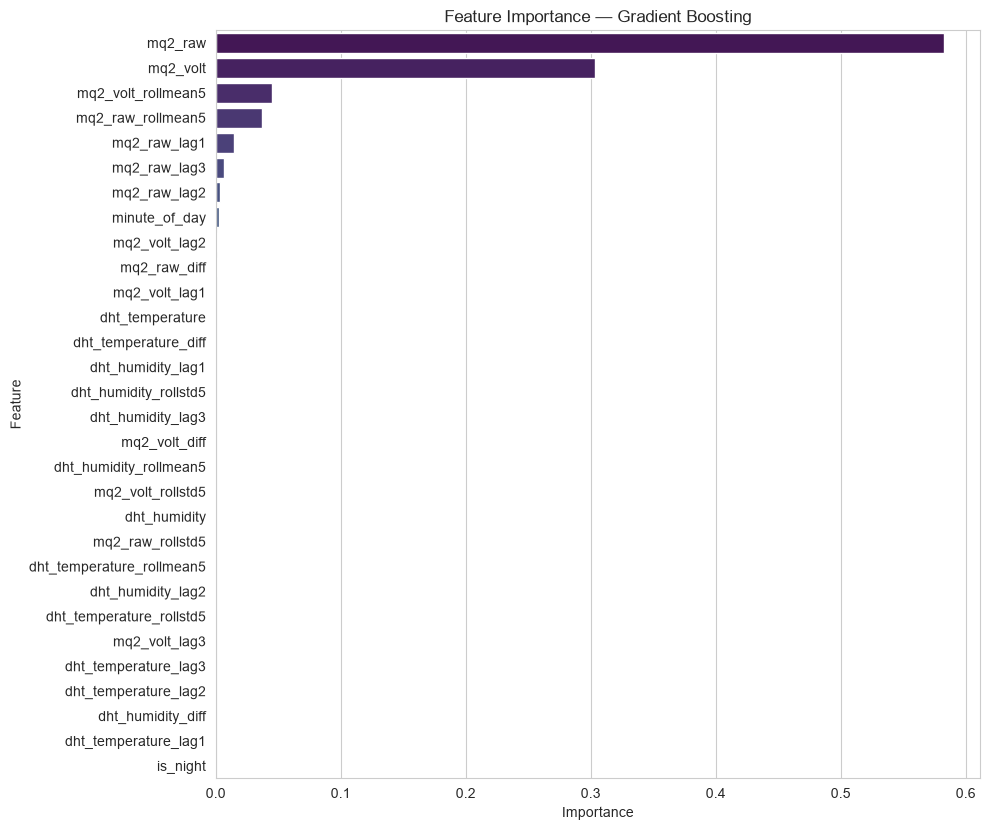

 Top fitur:
mq2_raw               0.582265
mq2_volt              0.303580
mq2_volt_rollmean5    0.044724
mq2_raw_rollmean5     0.037044
mq2_raw_lag1          0.014351
mq2_raw_lag3          0.006679
mq2_raw_lag2          0.003730
minute_of_day         0.002538
mq2_volt_lag2         0.000947
mq2_raw_diff          0.000642
dtype: float64


In [18]:
importances = pd.Series(gbr.feature_importances_, index=FEATURES)\
                .sort_values(ascending=False)

plt.figure(figsize=(10, max(5, len(FEATURES) * 0.28)))
sns.barplot(x=importances.values, y=importances.index, palette="viridis")
plt.title("Feature Importance — Gradient Boosting")
plt.xlabel("Importance"); plt.ylabel("Feature")
plt.tight_layout(); plt.show()

print(" Top fitur:")
print(importances.head(10))

## Simpan model dan metadata

In [19]:
ARTIFACT = {
    "model": gbr,
    "features": FEATURES,
    "threshold": SMOKE_THRESHOLD,
    "metrics_test": metrics_test,
    "trained_at": pd.Timestamp.now().isoformat(),
}

os.makedirs("models", exist_ok=True)
MODEL_PATH = "models/gbr_smoke_mq2.joblib"
joblib.dump(ARTIFACT, MODEL_PATH)
print(f" Model tersimpan di: {MODEL_PATH}")
print(f" Ukuran file: {os.path.getsize(MODEL_PATH)/1024:.1f} KB")

# --- Contoh load ulang & inferensi ---
loaded = joblib.load(MODEL_PATH)
sample = X_test[:5]
pred   = loaded["model"].predict(sample)
for i, p in enumerate(pred):
    status = " SMOKE " if p > loaded["threshold"] else " AMAN "
    print(f"  Sample-{i}: prediksi={p:.1f} -> {status}")

 Model tersimpan di: models/gbr_smoke_mq2.joblib
 Ukuran file: 532.2 KB
  Sample-0: prediksi=414.6 ->  AMAN 
  Sample-1: prediksi=413.9 ->  AMAN 
  Sample-2: prediksi=414.1 ->  AMAN 
  Sample-3: prediksi=413.1 ->  AMAN 
  Sample-4: prediksi=413.9 ->  AMAN 


kode di atas adalah pipeline machine learning lengkap untuk proyek smart home Anda, yang memakai Gradient Boosting Regressor untuk memprediksi nilai mq2_raw (ADC sensor asap MQ-2) satu langkah ke depan, sebagai pendapat kedua (second opinion) di samping alarm firmware ESP32 yang memakai threshold 700. Model tidak menggantikan alarm — hanya memberi prediksi tambahan.